# Heatmaps of 5' end positions of shRNA-derived small RNAs

# Re-written my code using Deepseek


This notebook reads the per-read `*.shrna.position.txt` files and draws one heatmap per shRNA backbone.

- **Rows**: 144 shRNA variants, labelled by serial number (001-144). With the compact figure height, only every 20th serial number is shown on the y axis.
- **Columns**: 5' end position of the small RNA (`rstart`, the 2nd column of the position file).
- **Values**: read count at a position / total reads of that variant x 100 (%).
- **Colour**: a single log colour scale from **1% to 100%**. 10% is at the midpoint because sqrt(1 x 100) = 10. Values below 1% (including 0) are shown in light grey. This avoids mixing linear and log scales.

Input files:

`/home/kwonschul/data/hku_NGS/42_novaseq49_241224/analysis-no-collapsing/annotated/{sample}.shrna.position.txt`

Each line in a position file is one read. The first column is the shRNA variant ID (e.g. `1mir33_1`) and the second column is the 5' end position (`rstart`).


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

mpl.rcParams['pdf.fonttype'] = 42
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 180)


In [2]:
# ----------------------------------------------------------------------
# Input / output
# ----------------------------------------------------------------------
DATA_DIR = Path('/home/kwonschul/data/hku_NGS/42_novaseq49_241224/analysis-no-collapsing/annotated')
NAME_FILE = Path('/home/kwonschul/data/hku_NGS/42_novaseq49_241224/analysis/papername2.txt')
OUT_DIR = Path('/home/kwonschul/projects/shrek/deepseek/heatmap/metrics_5end_v2')
OUT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLES = ['1mir33',
           '2mirGE',
           '3pGIPZ',
           '4J3',
           '6mir26',
           '8mir16',
           '9mir16ghg']

# ----------------------------------------------------------------------
# Heatmap options
# ----------------------------------------------------------------------
MIN_TOTAL_COUNT = 0        # 0 = keep all 144 variants; set e.g. 20 for an expression cutoff
POSITION_MIN = None        # None = smallest rstart observed in the data
POSITION_MAX = None        # None = largest rstart observed in the data
LOG_VMIN = 1.0             # lower limit of the log colour scale (%)
LOG_VMAX = 100.0           # upper limit of the log colour scale (%)
#CMAP_NAME = 'YlGnBu'
#CMAP_NAME = 'PuBu'
CMAP_NAME = 'PuRd'
UNDER_COLOR = '#f2f2f2'    # colour for 0% and values below LOG_VMIN
YLABEL_STEP = 20           # label every 20th variant at the compact figure height
FIG_SIZE = (10, 2)
SHOW_INTENDED_POSITIONS = True
SAVE_FIGURES = False

# Intended 5' end positions (taken from the original notebook)
GUIDE_POS = {'1mir33': 26,
             '2mirGE': 25,
             '3pGIPZ': 66,
             '4J3': 27,
             '6mir26': 27,
             '8mir16': 27,
             '9mir16ghg': 27}

PASSENGER_POS = {'1mir33': 65,
                 '2mirGE': 64,
                 '3pGIPZ': 27,
                 '4J3': 67,
                 '6mir26': 67,
                 '8mir16': 63,
                 '9mir16ghg': 63}


In [3]:
# Map library code (1mir33, 2mirGE, ...) to the paper name
dfName = pd.read_table(NAME_FILE)
D_LIBRARY_TO_PAPER = dict(zip(dfName['species'], dfName['papername']))

missing = [s for s in SAMPLES if s not in D_LIBRARY_TO_PAPER]
assert not missing, 'Missing sample names in {}: {}'.format(NAME_FILE, missing)

{s: D_LIBRARY_TO_PAPER[s] for s in SAMPLES}


{'1mir33': '1Xie2020',
 '2mirGE': '2Myburgh2014',
 '3pGIPZ': '3GIPZ',
 '4J3': '4Kong-J3',
 '6mir26': '5Kong-26',
 '8mir16': '7Kong-16',
 '9mir16ghg': '8Kong-16GHG'}

In [4]:
def read_position_counts(sample):
    """Read one *.shrna.position.txt file and count reads per (variant, rstart)."""
    path = DATA_DIR / '{}.shrna.position.txt'.format(sample)

    df = pd.read_csv(
        path,
        sep='\t',
        header=None,
        usecols=[0, 1],
        names=['shrek_species', 'rstart'],
        dtype={'shrek_species': 'string', 'rstart': 'int32'},
    )

    counts = (df.groupby(['shrek_species', 'rstart'], sort=False)
                .size()
                .reset_index(name='count'))

    counts['library'] = sample
    parts = counts['shrek_species'].str.split('_', n=1, expand=True)
    counts['species'] = parts[0]
    counts['serial'] = parts[1].str.zfill(3)
    counts['papername'] = counts['species'].map(D_LIBRARY_TO_PAPER)
    counts['variant_id'] = counts['papername'] + '_' + counts['serial']

    return counts


In [5]:
frames = []
for sample in SAMPLES:
    print('Reading {} ...'.format(sample), end=' ', flush=True)
    dfSample = read_position_counts(sample)
    print('{} variants, {:,} reads'.format(
        dfSample['shrek_species'].nunique(), dfSample['count'].sum()))
    frames.append(dfSample)

dfCounts = pd.concat(frames, ignore_index=True)
print('\nCombined long table:', dfCounts.shape)
dfCounts.head()


Reading 1mir33 ... 

144 variants, 4,580,832 reads
Reading 2mirGE ... 

144 variants, 1,845,793 reads
Reading 3pGIPZ ... 

144 variants, 1,024,565 reads
Reading 4J3 ... 

144 variants, 1,353,700 reads
Reading 6mir26 ... 

144 variants, 4,409,995 reads
Reading 8mir16 ... 

144 variants, 4,017,996 reads
Reading 9mir16ghg ... 

144 variants, 5,113,414 reads

Combined long table: (22105, 8)


,shrek_species,rstart,count,library,species,serial,papername,variant_id
0,1mir33_1,2,1,1mir33,1mir33,001,1Xie2020,1Xie2020_001
1,1mir33_1,3,1,1mir33,1mir33,001,1Xie2020,1Xie2020_001
2,1mir33_1,4,7,1mir33,1mir33,001,1Xie2020,1Xie2020_001
3,1mir33_1,5,13,1mir33,1mir33,001,1Xie2020,1Xie2020_001
4,1mir33_1,6,53,1mir33,1mir33,001,1Xie2020,1Xie2020_001


In [6]:
# Cross-check the summed position counts against the *.shrna.count.txt files
def read_count_file(sample):
    path = DATA_DIR / '{}.shrna.count.txt'.format(sample)
    return pd.read_csv(path, sep=r'\s+', header=None,
                       names=['count_file', 'shrek_species'])

validation = []
for sample in SAMPLES:
    dfC = read_count_file(sample).set_index('shrek_species')['count_file']
    dfP = (dfCounts[dfCounts['library'] == sample]
           .groupby('shrek_species')['count'].sum())
    joined = pd.concat([dfC, dfP], axis=1, join='outer').fillna(0)
    validation.append({
        'library': sample,
        'n_variants': len(joined),
        'max_abs_difference': (joined['count_file'] - joined['count']).abs().max(),
    })

dfValidation = pd.DataFrame(validation)
dfValidation


,library,n_variants,max_abs_difference
0,1mir33,144,0
1,2mirGE,144,0
2,3pGIPZ,144,0
3,4J3,144,0
4,6mir26,144,0
5,8mir16,144,0
6,9mir16ghg,144,0


In [7]:
# Total reads per variant, then percentage per position
group_cols = ['library', 'papername', 'variant_id', 'serial']

dfTotals = (dfCounts.groupby(group_cols, as_index=False)['count']
            .sum()
            .rename(columns={'count': 'total_count'}))

dfCounts = dfCounts.merge(dfTotals, on=group_cols, how='left', validate='many_to_one')
dfCounts['percent'] = 100.0 * dfCounts['count'] / dfCounts['total_count']

dfCounts.head()


,shrek_species,rstart,count,library,species,serial,papername,variant_id,total_count,percent
0,1mir33_1,2,1,1mir33,1mir33,001,1Xie2020,1Xie2020_001,21421,0.004668
1,1mir33_1,3,1,1mir33,1mir33,001,1Xie2020,1Xie2020_001,21421,0.004668
2,1mir33_1,4,7,1mir33,1mir33,001,1Xie2020,1Xie2020_001,21421,0.032678
3,1mir33_1,5,13,1mir33,1mir33,001,1Xie2020,1Xie2020_001,21421,0.060688
4,1mir33_1,6,53,1mir33,1mir33,001,1Xie2020,1Xie2020_001,21421,0.247421


In [8]:
# Build one 144 x n_position matrix per backbone
pos_min = int(dfCounts['rstart'].min()) if POSITION_MIN is None else POSITION_MIN
pos_max = int(dfCounts['rstart'].max()) if POSITION_MAX is None else POSITION_MAX
all_positions = np.arange(pos_min, pos_max + 1)

matrices = {}
for sample in SAMPLES:
    dfEach = dfCounts[dfCounts['library'] == sample]
    dfEach = dfEach[dfEach['total_count'] >= MIN_TOTAL_COUNT]
    serials = sorted(dfEach['serial'].unique())

    mat = (dfEach.pivot(index='serial', columns='rstart', values='percent')
                 .reindex(index=serials, columns=all_positions)
                 .fillna(0.0))
    matrices[sample] = mat

print('Positions: {}-{} ({} columns)'.format(pos_min, pos_max, len(all_positions)))
for sample, mat in matrices.items():
    print('{}: {} rows x {} columns'.format(sample, mat.shape[0], mat.shape[1]))


Positions: 0-94 (95 columns)
1mir33: 144 rows x 95 columns
2mirGE: 144 rows x 95 columns
3pGIPZ: 144 rows x 95 columns
4J3: 144 rows x 95 columns
6mir26: 144 rows x 95 columns
8mir16: 144 rows x 95 columns
9mir16ghg: 144 rows x 95 columns


In [9]:
def draw_position_heatmap(matrix, sample, output_dir=None):
    """Draw one compact heatmap: rows = variants, columns = 5' end positions."""
    fig, ax = plt.subplots(figsize=FIG_SIZE)

    cmap = plt.get_cmap(CMAP_NAME).copy()
    cmap.set_under(UNDER_COLOR)
    cmap.set_bad(UNDER_COLOR)

    # LogNorm cannot display 0; mask zeros and let values below LOG_VMIN use
    # the underflow colour. Both are drawn in the same light grey.
    values = np.ma.masked_where(matrix.values <= 0, matrix.values)
    norm = LogNorm(vmin=LOG_VMIN, vmax=LOG_VMAX, clip=False)

    im = ax.imshow(
        values,
        aspect='auto',
        interpolation='nearest',
        cmap=cmap,
        norm=norm,
        origin='upper',
    )

    # Rows: 144 variants; label every YLABEL_STEP-th variant at this compact height
    row_positions = list(range(0, matrix.shape[0], YLABEL_STEP))
    if row_positions[-1] != matrix.shape[0] - 1:
        row_positions.append(matrix.shape[0] - 1)
    ax.set_yticks(row_positions)
    ax.set_yticklabels([matrix.index[i] for i in row_positions], fontsize=6)
    ax.set_ylabel('shRNA variant (serial)', fontsize=6)

    # Columns: 5' end positions
    xtick_step = 5
    ax.set_xticks(np.arange(0, matrix.shape[1], xtick_step))
    ax.set_xticklabels(matrix.columns[::xtick_step], fontsize=6)
    ax.set_xlabel("5' end position (rstart, nt)", fontsize=7)

    # Mark the intended guide and passenger 5' ends
    if SHOW_INTENDED_POSITIONS:
        for pos, color, label, ls in [
            (GUIDE_POS[sample], '#d62728', "guide 5' end", '--'),
            (PASSENGER_POS[sample], '#1f77b4', "passenger 5' end", ':'),
        ]:
            if pos in matrix.columns:
                x = list(matrix.columns).index(pos)
                ax.axvline(x, color=color, linestyle=ls, linewidth=0.7, label=label)
        ax.legend(loc='upper right', fontsize=5, framealpha=0.85)

    papername = D_LIBRARY_TO_PAPER[sample]
    ax.set_title(
        '{} ({}) - 5\' end position (log 1-100%; <1 grey)'.format(sample, papername),
        fontsize=8,
        pad=4,
    )

    cbar = fig.colorbar(
        im, ax=ax, fraction=0.03, pad=0.02,
        extend='min', extendfrac=0.04,
    )
    cbar.set_label('% of total reads (log)', fontsize=6)
    colorbar_ticks = [1, 2, 5, 10, 20, 50, 100]
    cbar.set_ticks(colorbar_ticks)
    cbar.set_ticklabels(['{:g}'.format(t) for t in colorbar_ticks])
    cbar.ax.tick_params(labelsize=6)

    fig.tight_layout()

    if output_dir is not None:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        for ext in ['pdf', 'png']:
            fig.savefig(output_dir / 'heatmap_5end_{}.{}'.format(sample, ext),
                        dpi=300, bbox_inches='tight')

    return fig


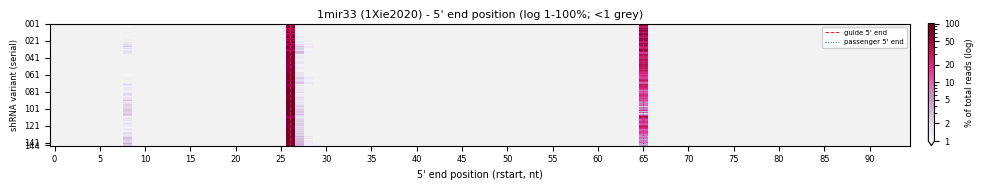

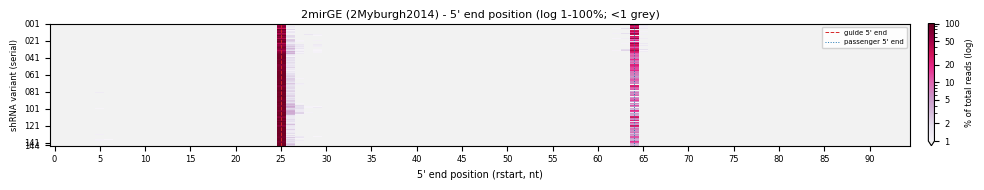

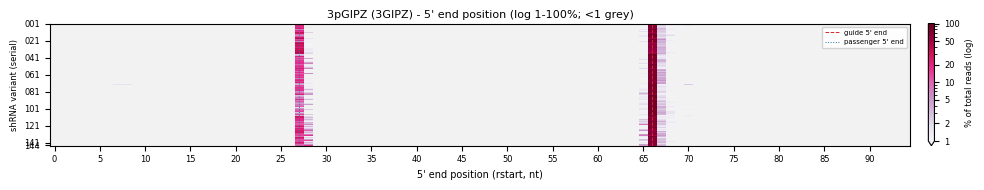

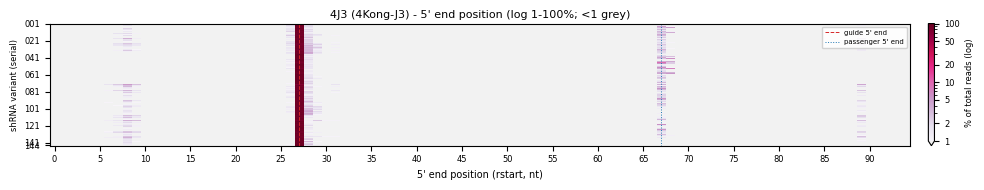

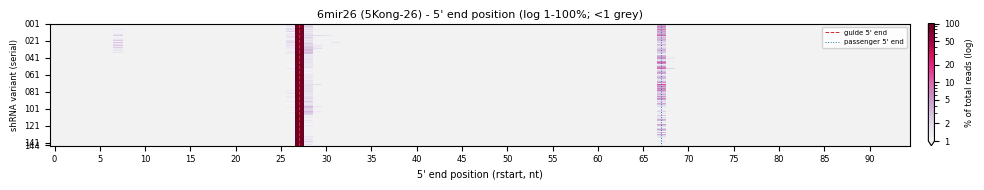

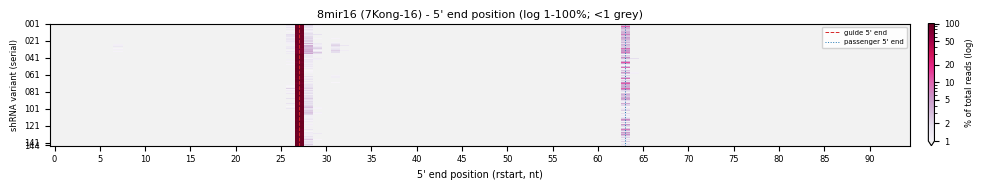

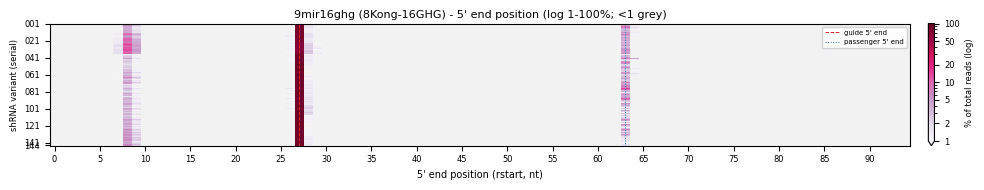

In [10]:
for sample in SAMPLES:
    fig = draw_position_heatmap(
        matrices[sample],
        sample,
        output_dir=OUT_DIR if SAVE_FIGURES else None,
    )
    plt.show()
    plt.close(fig)


In [11]:
# Save the long percentage table for downstream analysis
dfOutput = (dfCounts[['library', 'papername', 'variant_id', 'serial', 'rstart',
                      'count', 'total_count', 'percent']]
            .sort_values(['library', 'serial', 'rstart'])
            .reset_index(drop=True))

out_csv = OUT_DIR / 'shRNA_5end_position_percent.csv'
dfOutput.to_csv(out_csv, index=False)
print('Saved {:,} rows to {}'.format(len(dfOutput), out_csv))
dfOutput.head()


Saved 22,105 rows to /home/kwonschul/projects/shrek/deepseek/heatmap/metrics_5end_v2/shRNA_5end_position_percent.csv


,library,papername,variant_id,serial,rstart,count,total_count,percent
0,1mir33,1Xie2020,1Xie2020_001,001,2,1,21421,0.004668
1,1mir33,1Xie2020,1Xie2020_001,001,3,1,21421,0.004668
2,1mir33,1Xie2020,1Xie2020_001,001,4,7,21421,0.032678
3,1mir33,1Xie2020,1Xie2020_001,001,5,13,21421,0.060688
4,1mir33,1Xie2020,1Xie2020_001,001,6,53,21421,0.247421


In [12]:
# Summary of read depth per backbone
dfSummary = (dfTotals.groupby(['library', 'papername'])
             .agg(n_variants=('variant_id', 'nunique'),
                  total_reads=('total_count', 'sum'),
                  min_reads_per_variant=('total_count', 'min'),
                  median_reads_per_variant=('total_count', 'median'),
                  max_reads_per_variant=('total_count', 'max'))
             .reset_index())
dfSummary


,library,papername,n_variants,total_reads,min_reads_per_variant,median_reads_per_variant,max_reads_per_variant
0,1mir33,1Xie2020,144,4580832,11557,28231.5,80451
1,2mirGE,2Myburgh2014,144,1845793,4297,10876.5,31647
2,3pGIPZ,3GIPZ,144,1024565,328,6430.5,19619
3,4J3,4Kong-J3,144,1353700,1219,5447.0,54400
4,6mir26,5Kong-26,144,4409995,3322,25833.5,91511
5,8mir16,7Kong-16,144,4017996,3564,24541.5,97327
6,9mir16ghg,8Kong-16GHG,144,5113414,9835,32538.5,98680


# Additional figures: small RNA metrics

These cells use the same `dfCounts` table built above and calculate four per-variant metrics, following the definitions in the original template notebook.

| Metric | Definition |
|---|---|
| **Small RNA homogeneity** | reads at `GUIDE_POS` / total reads x 100 |
| **Guide heterogeneity** | (reads in `GUIDE_POS +/-6 nt` - reads at `GUIDE_POS`) / reads in `GUIDE_POS +/-6 nt` x 100 |
| **Passenger retention** | reads in `PASSENGER_POS +/-6 nt` / (reads in guide window + reads in passenger window) x 100 |
| **Outliers** | (total reads - reads in guide window - reads in passenger window) / total reads x 100 |

`GUIDE_POS` and `PASSENGER_POS` are defined in the configuration cell above. For pGIPZ (a 3' shRNA), the guide 5' end is at 66 and the passenger 5' end at 27; for the other backbones the guide is at 25-27 and the passenger at 63-67.


In [13]:
import seaborn as sns
from scipy import stats
from IPython.display import display

METRICS_OUT_DIR = OUT_DIR
METRICS_OUT_DIR.mkdir(parents=True, exist_ok=True)
PAIRWISE_OUT_DIR = METRICS_OUT_DIR / '3pGIPZ_vs_6mir26'
PAIRWISE_OUT_DIR.mkdir(parents=True, exist_ok=True)
SAVE_METRICS = True

# v2 removes one backbone (7mir26ghg). Scale the width of the metrics figures
# by 7/8 so every box keeps roughly the same physical width as before.
N_METRIC_GROUPS = len(SAMPLES)                 # 7
METRICS_WIDTH_SCALE = N_METRIC_GROUPS / 8.0    # 0.875
METRICS_COMBINED_SIZE = (13 * METRICS_WIDTH_SCALE, 9)    # 11.375 x 9 in
METRICS_INDIVIDUAL_SIZE = (7 * METRICS_WIDTH_SCALE, 5)   # 6.125 x 5 in

# Pairwise 3pGIPZ vs 6mir26 figure width: 33% of the previous width;
# heights are unchanged.
PAIRWISE_WIDTH_FRACTION = 0.33
PAIRWISE_COMBINED_WIDTH = 10.0 * PAIRWISE_WIDTH_FRACTION      # 3.3 in
PAIRWISE_COMBINED_HEIGHT = 8.0
PAIRWISE_INDIVIDUAL_WIDTH = 5.5 * PAIRWISE_WIDTH_FRACTION    # 1.815 in
PAIRWISE_INDIVIDUAL_HEIGHT = 5.0


## Schematic of the four metrics

The diagram below explains how the four per-variant metrics are defined. The example shows a 5p backbone with `GUIDE_POS = 27` and `PASSENGER_POS = 65`; for pGIPZ (3p shRNA) the guide and passenger positions are swapped.


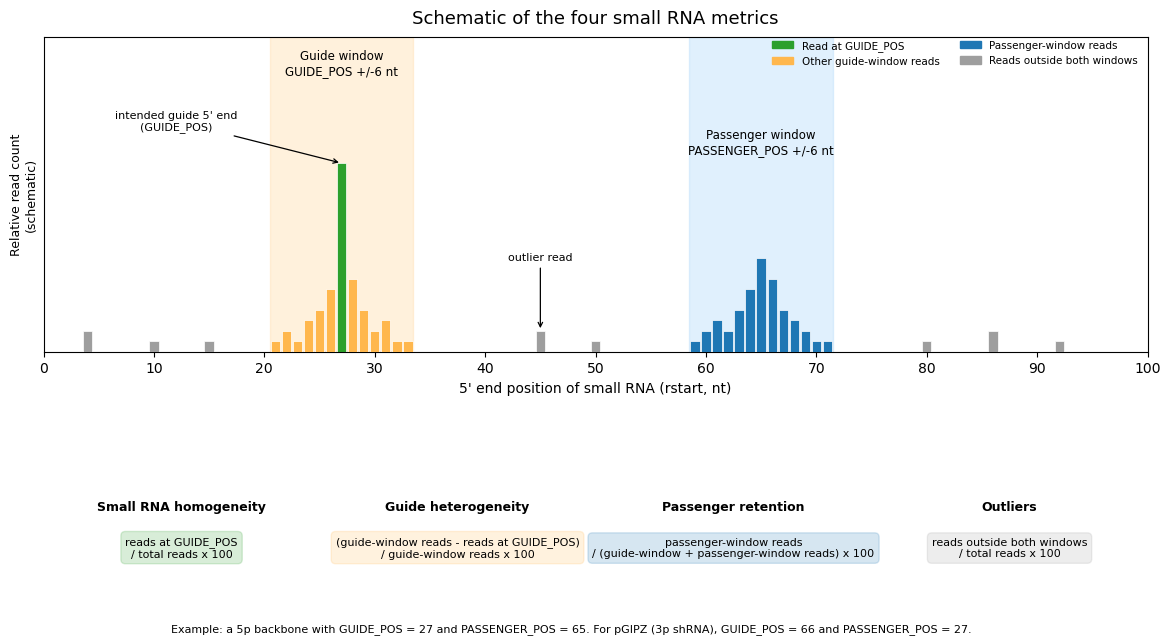

In [14]:
import matplotlib.patches as mpatches

# Conceptual example: a 5p backbone with the guide at 27 and passenger at 65
nGuidePos = 27
nPassPos = 65
nWindow = 6

dGuideWindow = {21: 1, 22: 2, 23: 1, 24: 3, 25: 4, 26: 6, 27: 18,
                28: 7, 29: 4, 30: 2, 31: 3, 32: 1, 33: 1}
dPassWindow = {59: 1, 60: 2, 61: 3, 62: 2, 63: 4, 64: 6, 65: 9,
               66: 7, 67: 4, 68: 3, 69: 2, 70: 1, 71: 1}
dOutliers = {4: 2, 10: 1, 15: 1, 45: 2, 50: 1, 80: 1, 86: 2, 92: 1}

dAll = {}
dAll.update(dOutliers)
dAll.update(dGuideWindow)
dAll.update(dPassWindow)

lPositions = sorted(dAll)
lHeights = [dAll[position] for position in lPositions]
lColors = []
for position in lPositions:
    if position == nGuidePos:
        lColors.append('#2ca02c')          # intended guide 5' end
    elif abs(position - nGuidePos) <= nWindow:
        lColors.append('#ffb74d')          # other guide-window starts
    elif abs(position - nPassPos) <= nWindow:
        lColors.append('#1f77b4')          # passenger-window starts
    else:
        lColors.append('#9e9e9e')          # outside both windows

fig = plt.figure(figsize=(12, 6.5))
gs = fig.add_gridspec(2, 1, height_ratios=[3.2, 1.0], hspace=0.55)
ax = fig.add_subplot(gs[0])
axText = fig.add_subplot(gs[1])
axText.axis('off')

# Shaded guide and passenger windows
ax.axvspan(nGuidePos - nWindow - 0.5, nGuidePos + nWindow + 0.5,
           color='#ffe0b2', alpha=0.45, zorder=0)
ax.axvspan(nPassPos - nWindow - 0.5, nPassPos + nWindow + 0.5,
           color='#bbdefb', alpha=0.45, zorder=0)

ax.bar(lPositions, lHeights, color=lColors, width=0.85,
       edgecolor='white', linewidth=0.5, zorder=3)

ax.set_xlim(0, 100)
ax.set_ylim(0, 30)
ax.set_xticks(np.arange(0, 101, 10))
ax.set_xlabel("5' end position of small RNA (rstart, nt)", fontsize=10)
ax.set_ylabel('Relative read count\n(schematic)', fontsize=9)
ax.set_yticks([])
ax.set_title('Schematic of the four small RNA metrics', fontsize=13, pad=10)

ax.text(nGuidePos, 27.5, 'Guide window\nGUIDE_POS +/-6 nt',
        ha='center', va='center', fontsize=8.5)
ax.text(nPassPos, 20.0, 'Passenger window\nPASSENGER_POS +/-6 nt',
        ha='center', va='center', fontsize=8.5)

ax.annotate("intended guide 5' end\n(GUIDE_POS)",
            xy=(nGuidePos, 18), xytext=(12, 22),
            ha='center', va='center', fontsize=8,
            arrowprops=dict(arrowstyle='->', color='black', lw=0.9))
ax.annotate('outlier read',
            xy=(45, 2), xytext=(45, 9),
            ha='center', va='center', fontsize=8,
            arrowprops=dict(arrowstyle='->', color='black', lw=0.9))

lHandles = [
    mpatches.Patch(color='#2ca02c', label='Read at GUIDE_POS'),
    mpatches.Patch(color='#ffb74d', label='Other guide-window reads'),
    mpatches.Patch(color='#1f77b4', label='Passenger-window reads'),
    mpatches.Patch(color='#9e9e9e', label='Reads outside both windows'),
]
ax.legend(handles=lHandles, loc='upper right', fontsize=7.5, ncol=2,
          frameon=False, bbox_to_anchor=(1.0, 1.02))

formula_items = [
    ('Small RNA homogeneity',
     'reads at GUIDE_POS\n/ total reads x 100',
     '#2ca02c'),
    ('Guide heterogeneity',
     '(guide-window reads - reads at GUIDE_POS)\n/ guide-window reads x 100',
     '#ffb74d'),
    ('Passenger retention',
     'passenger-window reads\n/ (guide-window + passenger-window reads) x 100',
     '#1f77b4'),
    ('Outliers',
     'reads outside both windows\n/ total reads x 100',
     '#9e9e9e'),
]
for i, (sTitle, sFormula, sColor) in enumerate(formula_items):
    x = 0.125 + i * 0.25
    axText.text(x, 0.58, sTitle, transform=axText.transAxes,
                ha='center', va='center', fontsize=9, fontweight='bold')
    axText.text(x, 0.16, sFormula, transform=axText.transAxes,
                ha='center', va='center', fontsize=8,
                bbox=dict(boxstyle='round,pad=0.4', facecolor=sColor,
                          alpha=0.18, edgecolor=sColor, linewidth=1.0))

fig.text(0.5, 0.012,
         'Example: a 5p backbone with GUIDE_POS = 27 and PASSENGER_POS = 65. '
         'For pGIPZ (3p shRNA), GUIDE_POS = 66 and PASSENGER_POS = 27.',
         ha='center', va='bottom', fontsize=8)
fig.subplots_adjust(left=0.06, right=0.98, top=0.93, bottom=0.12)

if SAVE_METRICS:
    for ext in ['pdf', 'png']:
        fig.savefig(METRICS_OUT_DIR / 'metrics_5end_schematic.{}'.format(ext),
                    dpi=300, bbox_inches='tight')
plt.show()


In [15]:
# Window size around the intended 5' ends (same as the original template)
GUIDE_WINDOW = 6
PASSENGER_WINDOW = 6

# Minimum total reads for a variant to be included in the metric plots
MIN_TOTAL_COUNT_METRICS = 20
REQUIRE_ALL_BACKBONES = True

dfMetricInput = dfCounts.copy()
dfMetricInput['guide_pos'] = dfMetricInput['library'].map(GUIDE_POS)
dfMetricInput['passenger_pos'] = dfMetricInput['library'].map(PASSENGER_POS)

dfMetricInput['in_guide'] = dfMetricInput['rstart'].eq(dfMetricInput['guide_pos'])
dfMetricInput['in_guide_region'] = (
    (dfMetricInput['rstart'] >= dfMetricInput['guide_pos'] - GUIDE_WINDOW)
    & (dfMetricInput['rstart'] <= dfMetricInput['guide_pos'] + GUIDE_WINDOW)
)
dfMetricInput['in_passenger_region'] = (
    (dfMetricInput['rstart'] >= dfMetricInput['passenger_pos'] - PASSENGER_WINDOW)
    & (dfMetricInput['rstart'] <= dfMetricInput['passenger_pos'] + PASSENGER_WINDOW)
)

dfMetricInput['count_guide'] = dfMetricInput['count'] * dfMetricInput['in_guide'].astype(int)
dfMetricInput['count_guide_region'] = dfMetricInput['count'] * dfMetricInput['in_guide_region'].astype(int)
dfMetricInput['count_passenger_region'] = dfMetricInput['count'] * dfMetricInput['in_passenger_region'].astype(int)

dfMetrics = (dfMetricInput
    .groupby(['library', 'papername', 'variant_id', 'serial'], as_index=False)
    .agg(total_count=('count', 'sum'),
         guide_count=('count_guide', 'sum'),
         guide_region_count=('count_guide_region', 'sum'),
         passenger_region_count=('count_passenger_region', 'sum')))

def percent_or_nan(numerator, denominator):
    numerator = np.asarray(numerator, dtype=float)
    denominator = np.asarray(denominator, dtype=float)
    out = np.full(numerator.shape, np.nan)
    np.divide(numerator, denominator, out=out, where=denominator > 0)
    return out * 100.0

dfMetrics['homogeneity_percent'] = percent_or_nan(
    dfMetrics['guide_count'], dfMetrics['total_count'])
dfMetrics['heterogeneity_percent'] = percent_or_nan(
    dfMetrics['guide_region_count'] - dfMetrics['guide_count'],
    dfMetrics['guide_region_count'])
dfMetrics['maturation_percent'] = percent_or_nan(
    dfMetrics['passenger_region_count'],
    dfMetrics['guide_region_count'] + dfMetrics['passenger_region_count'])
dfMetrics['outlier_percent'] = percent_or_nan(
    dfMetrics['total_count'] - dfMetrics['guide_region_count'] - dfMetrics['passenger_region_count'],
    dfMetrics['total_count'])

print('Metrics table:', dfMetrics.shape)
dfMetrics.head()


Metrics table: (1008, 12)


,library,papername,variant_id,serial,total_count,guide_count,guide_region_count,passenger_region_count,homogeneity_percent,heterogeneity_percent,maturation_percent,outlier_percent
0,1mir33,1Xie2020,1Xie2020_001,001,21421,7709,8125,12746,35.988049,5.120000,61.070385,2.567574
1,1mir33,1Xie2020,1Xie2020_002,002,46398,27990,29000,16838,60.325876,3.482759,36.733714,1.206949
2,1mir33,1Xie2020,1Xie2020_003,003,42862,19863,20667,21630,46.341748,3.890260,51.138379,1.318184
3,1mir33,1Xie2020,1Xie2020_004,004,42562,23811,24879,17155,55.944270,4.292777,40.812200,1.240543
4,1mir33,1Xie2020,1Xie2020_005,005,34636,22566,23465,10694,65.151865,3.831238,31.306537,1.377180


In [16]:
# Apply the expression cutoff and keep variants measured in all backbones
dfMetricsFiltered = dfMetrics[dfMetrics['total_count'] >= MIN_TOTAL_COUNT_METRICS].copy()

if REQUIRE_ALL_BACKBONES:
    n_backbones = dfMetricsFiltered.groupby('serial')['library'].nunique()
    common_serials = n_backbones[n_backbones == len(SAMPLES)].index
    dfMetricsFiltered = dfMetricsFiltered[dfMetricsFiltered['serial'].isin(common_serials)].copy()

n_common = dfMetricsFiltered['serial'].nunique()
print('Variants used in the plots:', n_common)
print(dfMetricsFiltered.groupby('library')['serial'].nunique())

METRIC_SPECS = [
    ('homogeneity_percent', 'Small RNA homogeneity', 'metrics_5end_homogeneity'),
    ('heterogeneity_percent', 'Guide heterogeneity', 'metrics_5end_heterogeneity'),
    ('maturation_percent', 'Passenger retention', 'metrics_5end_passenger_retention'),
    ('outlier_percent', 'Outliers', 'metrics_5end_outliers'),
]
D_METRIC_LABEL = {metric: label for metric, label, _ in METRIC_SPECS}
metric_columns = [metric for metric, _, _ in METRIC_SPECS]

dfMetricsLong = dfMetricsFiltered.melt(
    id_vars=['library', 'papername', 'serial'],
    value_vars=metric_columns,
    var_name='metric',
    value_name='percent')

dfMetricsSummary = (dfMetricsLong
    .groupby(['metric', 'library', 'papername'])['percent']
    .agg(n='count', median='median', mean='mean', sd='std')
    .reset_index())
dfMetricsSummary['metric_label'] = dfMetricsSummary['metric'].map(D_METRIC_LABEL)
dfMetricsSummary = dfMetricsSummary[['metric_label', 'metric', 'library', 'papername',
                                     'n', 'median', 'mean', 'sd']]
dfMetricsSummary


Variants used in the plots: 144
library
1mir33       144
2mirGE       144
3pGIPZ       144
4J3          144
6mir26       144
8mir16       144
9mir16ghg    144
Name: serial, dtype: int64


,metric_label,metric,library,papername,n,median,mean,sd
0,Guide heterogeneity,heterogeneity_percent,1mir33,1Xie2020,144,4.585378,4.794976,1.457953
1,Guide heterogeneity,heterogeneity_percent,2mirGE,2Myburgh2014,144,4.375974,4.936872,1.748902
2,Guide heterogeneity,heterogeneity_percent,3pGIPZ,3GIPZ,144,7.141734,7.524513,2.844172
3,Guide heterogeneity,heterogeneity_percent,4J3,4Kong-J3,144,4.818561,5.159736,1.709292
4,Guide heterogeneity,heterogeneity_percent,6mir26,5Kong-26,144,4.377905,4.605921,1.623472
5,Guide heterogeneity,heterogeneity_percent,8mir16,7Kong-16,144,4.306591,4.721083,1.952448
6,Guide heterogeneity,heterogeneity_percent,9mir16ghg,8Kong-16GHG,144,3.580378,4.003156,1.572011
7,Small RNA homogeneity,homogeneity_percent,1mir33,1Xie2020,144,73.273089,70.139957,13.982873
8,Small RNA homogeneity,homogeneity_percent,2mirGE,2Myburgh2014,144,84.758282,79.727118,12.926692
9,Small RNA homogeneity,homogeneity_percent,3pGIPZ,3GIPZ,144,75.335211,74.017212,9.943409


In [17]:
REFERENCE_SAMPLE = '6mir26'
ORDER_GROUPS = [REFERENCE_SAMPLE] + [s for s in SAMPLES if s != REFERENCE_SAMPLE]

def bh_adjust(p_values):
    """Benjamini-Hochberg FDR adjustment."""
    p_values = np.asarray(p_values, dtype=float)
    n = len(p_values)
    if n == 0:
        return p_values
    order = np.argsort(p_values)
    ranked = p_values[order]
    q_values = ranked * n / np.arange(1, n + 1)
    q_values = np.minimum.accumulate(q_values[::-1])[::-1]
    q_values = np.clip(q_values, 0, 1)
    out = np.empty(n, dtype=float)
    out[order] = q_values
    return out

def stars_from_q(q):
    if pd.isna(q):
        return 'NA'
    if q < 1e-4:
        return '****'
    if q < 1e-3:
        return '***'
    if q < 1e-2:
        return '**'
    if q < 0.05:
        return '*'
    return 'ns'

def format_p(p):
    if pd.isna(p):
        return 'NA'
    if p < 1e-3:
        return '{:.1e}'.format(p)
    return '{:.3f}'.format(p)

def mannwhitney_table(df, metric, reference, order):
    ref_vals = df.loc[df['library'] == reference, metric].dropna()
    rows = []
    for sample in order:
        if sample == reference:
            continue
        vals = df.loc[df['library'] == sample, metric].dropna()
        u_stat, p_val = stats.mannwhitneyu(ref_vals, vals, alternative='two-sided')
        rows.append({
            'metric': metric,
            'reference': reference,
            'comparison': sample,
            'n_reference': len(ref_vals),
            'n_comparison': len(vals),
            'median_reference': ref_vals.median(),
            'median_comparison': vals.median(),
            'median_difference': vals.median() - ref_vals.median(),
            'U': u_stat,
            'p_value': p_val,
        })
    out = pd.DataFrame(rows)
    out['q_value_bh'] = bh_adjust(out['p_value'])
    out['significance'] = out['q_value_bh'].apply(stars_from_q)
    return out

dfStatsAll = pd.concat(
    [mannwhitney_table(dfMetricsFiltered, metric, REFERENCE_SAMPLE, ORDER_GROUPS)
     for metric, _, _ in METRIC_SPECS],
    ignore_index=True)
dfStatsAll['metric_label'] = dfStatsAll['metric'].map(D_METRIC_LABEL)
dfStatsAll = dfStatsAll[['metric_label', 'metric', 'reference', 'comparison',
                     'n_reference', 'n_comparison',
                     'median_reference', 'median_comparison', 'median_difference',
                     'U', 'p_value', 'q_value_bh', 'significance']]

display(dfStatsAll)
display(dfStatsAll.pivot_table(index='metric_label', columns='comparison',
                             values='q_value_bh').reindex([D_METRIC_LABEL[m] for m, _, _ in METRIC_SPECS]))


,metric_label,metric,reference,comparison,n_reference,n_comparison,median_reference,median_comparison,median_difference,U,p_value,q_value_bh,significance
0,Small RNA homogeneity,homogeneity_percent,6mir26,1mir33,144,144,91.644171,73.273089,-18.371082,20164.0,1.085982e-43,6.515890e-43,****
1,Small RNA homogeneity,homogeneity_percent,6mir26,2mirGE,144,144,91.644171,84.758282,-6.885889,17829.0,4.706823e-26,9.413646e-26,****
2,Small RNA homogeneity,homogeneity_percent,6mir26,3pGIPZ,144,144,91.644171,75.335211,-16.308960,19917.0,1.331588e-41,3.994765e-41,****
3,Small RNA homogeneity,homogeneity_percent,6mir26,4J3,144,144,91.644171,88.168206,-3.475965,15340.0,1.992019e-12,2.390423e-12,****
4,Small RNA homogeneity,homogeneity_percent,6mir26,8mir16,144,144,91.644171,92.126405,0.482235,10298.0,9.216562e-01,9.216562e-01,ns
5,Small RNA homogeneity,homogeneity_percent,6mir26,9mir16ghg,144,144,91.644171,86.088050,-5.556121,17723.0,2.299728e-25,3.449591e-25,****
6,Guide heterogeneity,heterogeneity_percent,6mir26,1mir33,144,144,4.377905,4.585378,0.207473,9409.0,1.749883e-01,2.148883e-01,ns
7,Guide heterogeneity,heterogeneity_percent,6mir26,2mirGE,144,144,4.377905,4.375974,-0.001931,9418.0,1.790736e-01,2.148883e-01,ns
8,Guide heterogeneity,heterogeneity_percent,6mir26,3pGIPZ,144,144,4.377905,7.141734,2.763828,3035.0,3.187512e-25,1.912507e-24,****
9,Guide heterogeneity,heterogeneity_percent,6mir26,4J3,144,144,4.377905,4.818561,0.440655,8418.0,5.803407e-03,1.160681e-02,*


comparison,1mir33,2mirGE,3pGIPZ,4J3,8mir16,9mir16ghg
metric_label,,,,,,
Small RNA homogeneity,6.515890e-43,9.413646e-26,3.994765e-41,2.390423e-12,0.921656,3.449591e-25
Guide heterogeneity,2.148883e-01,2.148883e-01,1.912507e-24,1.160681e-02,0.857932,6.367875e-04
Passenger retention,3.134770e-42,8.003934e-28,1.438100e-41,7.689568e-03,0.983630,1.287296e-04
Outliers,2.271579e-18,4.455010e-03,1.016218e-05,3.993986e-27,0.541461,4.340362e-45


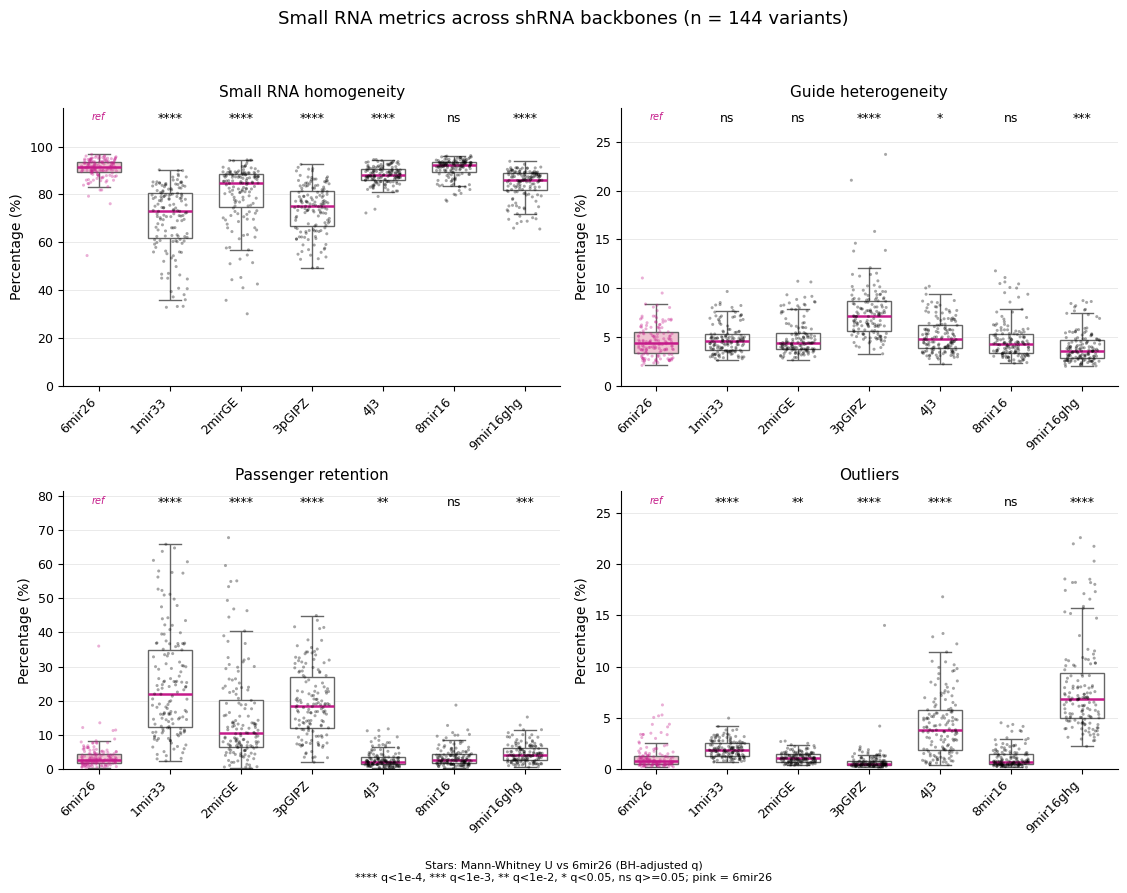

In [18]:
def draw_metric_boxplot_groups(ax, metric, title, show_comparison_title=False):
    box_colors = {s: ('#f8bbd0' if s == REFERENCE_SAMPLE else 'white') for s in ORDER_GROUPS}
    point_colors = {s: ('#c51b8a' if s == REFERENCE_SAMPLE else 'black') for s in ORDER_GROUPS}

    sns.boxplot(
        data=dfMetricsFiltered,
        x='library', y=metric, order=ORDER_GROUPS, hue_order=ORDER_GROUPS,
        hue='library', palette=box_colors, dodge=False,
        width=0.62, linewidth=1.0, showfliers=False,
        medianprops={'color': '#c51b8a', 'linewidth': 1.8},
        whiskerprops={'color': '#666666'},
        capprops={'color': '#666666'},
        boxprops={'edgecolor': '#666666'},
        ax=ax,
    )
    sns.stripplot(
        data=dfMetricsFiltered,
        x='library', y=metric, order=ORDER_GROUPS, hue_order=ORDER_GROUPS,
        hue='library', palette=point_colors, dodge=False,
        size=2.2, alpha=0.35, jitter=0.25,
        ax=ax,
    )

    if hasattr(ax, 'legend_') and ax.legend_ is not None:
        ax.legend_.remove()

    y_top = dfMetricsFiltered[metric].max() * 1.20
    ax.set_ylim(0, y_top)

    # Stars vs the reference (BH-adjusted q)
    for i, sample in enumerate(ORDER_GROUPS):
        if sample == REFERENCE_SAMPLE:
            ax.text(i, y_top * 0.985, 'ref', ha='center', va='top',
                    fontsize=7, color='#c51b8a', style='italic')
            continue
        row = dfStatsAll[(dfStatsAll['metric'] == metric) &
                       (dfStatsAll['comparison'] == sample)]
        if len(row) > 0:
            ax.text(i, y_top * 0.985, row.iloc[0]['significance'],
                    ha='center', va='top', fontsize=9)

    title_text = title
    if show_comparison_title:
        title_text += ' (vs {})'.format(REFERENCE_SAMPLE)
    ax.set_title(title_text, fontsize=11, pad=8)
    ax.set_xlabel('')
    ax.set_ylabel('Percentage (%)', fontsize=10)
    ax.tick_params(axis='x', labelrotation=45, labelsize=9)
    ax.tick_params(axis='y', labelsize=9)
    for label in ax.get_xticklabels():
        label.set_ha('right')
    ax.yaxis.grid(True, color='#e6e6e6', linewidth=0.6)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

STAR_NOTE = ('Stars: Mann-Whitney U vs {} (BH-adjusted q)\n'
             '**** q<1e-4, *** q<1e-3, ** q<1e-2, * q<0.05, ns q>=0.05; pink = {}'
             .format(REFERENCE_SAMPLE, REFERENCE_SAMPLE))

# Combined 2 x 2 panel
fig, axes = plt.subplots(2, 2, figsize=METRICS_COMBINED_SIZE)
for ax, (metric, title, _) in zip(axes.ravel(), METRIC_SPECS):
    draw_metric_boxplot_groups(ax, metric, title)
fig.suptitle('Small RNA metrics across shRNA backbones (n = {} variants)'.format(n_common), fontsize=13)
fig.text(0.5, 0.01, STAR_NOTE, ha='center', va='bottom', fontsize=8, linespacing=1.2)
fig.tight_layout(rect=[0, 0.045, 1, 0.95])

if SAVE_METRICS:
    for ext in ['pdf', 'png']:
        fig.savefig(METRICS_OUT_DIR / 'metrics_5end_combined.{}'.format(ext),
                    dpi=300, bbox_inches='tight')
plt.show()

# Individual figures
if SAVE_METRICS:
    for metric, title, stem in METRIC_SPECS:
        fig, ax = plt.subplots(figsize=METRICS_INDIVIDUAL_SIZE)
        draw_metric_boxplot_groups(ax, metric, title, show_comparison_title=True)
        fig.text(0.5, 0.01, STAR_NOTE, ha='center', va='bottom', fontsize=7.5, linespacing=1.2)
        fig.tight_layout(rect=[0, 0.07, 1, 1])
        for ext in ['pdf', 'png']:
            fig.savefig(METRICS_OUT_DIR / '{}.{}'.format(stem, ext),
                        dpi=300, bbox_inches='tight')
        plt.close(fig)


In [19]:
if SAVE_METRICS:
    dfMetrics.to_csv(METRICS_OUT_DIR / 'shRNA_metrics_5end_all_variants.csv', index=False)
    dfMetricsFiltered.to_csv(METRICS_OUT_DIR / 'shRNA_metrics_5end_plot_data.csv', index=False)
    dfMetricsSummary.to_csv(METRICS_OUT_DIR / 'shRNA_metrics_5end_summary.csv', index=False)
    dfStatsAll.to_csv(METRICS_OUT_DIR / 'shRNA_metrics_5end_stats_vs_6mir26.csv', index=False)
    print('Saved metric tables and 7-backbone statistics to {}'.format(METRICS_OUT_DIR))

dfStatsAll.head(10)


Saved metric tables and 7-backbone statistics to /home/kwonschul/projects/shrek/deepseek/heatmap/metrics_5end_v2


,metric_label,metric,reference,comparison,n_reference,n_comparison,median_reference,median_comparison,median_difference,U,p_value,q_value_bh,significance
0,Small RNA homogeneity,homogeneity_percent,6mir26,1mir33,144,144,91.644171,73.273089,-18.371082,20164.0,1.085982e-43,6.515890e-43,****
1,Small RNA homogeneity,homogeneity_percent,6mir26,2mirGE,144,144,91.644171,84.758282,-6.885889,17829.0,4.706823e-26,9.413646e-26,****
2,Small RNA homogeneity,homogeneity_percent,6mir26,3pGIPZ,144,144,91.644171,75.335211,-16.308960,19917.0,1.331588e-41,3.994765e-41,****
3,Small RNA homogeneity,homogeneity_percent,6mir26,4J3,144,144,91.644171,88.168206,-3.475965,15340.0,1.992019e-12,2.390423e-12,****
4,Small RNA homogeneity,homogeneity_percent,6mir26,8mir16,144,144,91.644171,92.126405,0.482235,10298.0,9.216562e-01,9.216562e-01,ns
5,Small RNA homogeneity,homogeneity_percent,6mir26,9mir16ghg,144,144,91.644171,86.088050,-5.556121,17723.0,2.299728e-25,3.449591e-25,****
6,Guide heterogeneity,heterogeneity_percent,6mir26,1mir33,144,144,4.377905,4.585378,0.207473,9409.0,1.749883e-01,2.148883e-01,ns
7,Guide heterogeneity,heterogeneity_percent,6mir26,2mirGE,144,144,4.377905,4.375974,-0.001931,9418.0,1.790736e-01,2.148883e-01,ns
8,Guide heterogeneity,heterogeneity_percent,6mir26,3pGIPZ,144,144,4.377905,7.141734,2.763828,3035.0,3.187512e-25,1.912507e-24,****
9,Guide heterogeneity,heterogeneity_percent,6mir26,4J3,144,144,4.377905,4.818561,0.440655,8418.0,5.803407e-03,1.160681e-02,*


## Pairwise comparison: 3pGIPZ vs 6mir26

The same four metrics are plotted for only these two backbones. For each metric, a two-sided Mann-Whitney U test is performed between 3pGIPZ and 6mir26. The bracket on each plot shows the raw p value; the table also includes the Benjamini-Hochberg adjusted q value across the four metrics.


In [20]:
PAIR_A = '3pGIPZ'
PAIR_B = '6mir26'
ORDER_2 = [PAIR_A, PAIR_B]

pair_rows = []
for metric, label, _ in METRIC_SPECS:
    vals_a = dfMetricsFiltered.loc[dfMetricsFiltered['library'] == PAIR_A, metric].dropna()
    vals_b = dfMetricsFiltered.loc[dfMetricsFiltered['library'] == PAIR_B, metric].dropna()
    u_stat, p_val = stats.mannwhitneyu(vals_a, vals_b, alternative='two-sided')
    pair_rows.append({
        'metric': metric,
        'metric_label': label,
        'group_a': PAIR_A,
        'group_b': PAIR_B,
        'n_a': len(vals_a),
        'n_b': len(vals_b),
        'median_a': vals_a.median(),
        'median_b': vals_b.median(),
        'median_difference': vals_b.median() - vals_a.median(),
        'U': u_stat,
        'p_value': p_val,
    })

dfStats2 = pd.DataFrame(pair_rows)
dfStats2['q_value_bh'] = bh_adjust(dfStats2['p_value'])
dfStats2['significance'] = dfStats2['q_value_bh'].apply(stars_from_q)
dfStats2 = dfStats2[['metric_label', 'metric', 'group_a', 'group_b', 'n_a', 'n_b',
                     'median_a', 'median_b', 'median_difference',
                     'U', 'p_value', 'q_value_bh', 'significance']]
dfStats2


,metric_label,metric,group_a,group_b,n_a,n_b,median_a,median_b,median_difference,U,p_value,q_value_bh,significance
0,Small RNA homogeneity,homogeneity_percent,3pGIPZ,6mir26,144,144,75.335211,91.644171,16.308960,819.0,1.331588e-41,2.663177e-41,****
1,Guide heterogeneity,heterogeneity_percent,3pGIPZ,6mir26,144,144,7.141734,4.377905,-2.763828,17701.0,3.187512e-25,4.250017e-25,****
2,Passenger retention,maturation_percent,3pGIPZ,6mir26,144,144,18.394739,2.790680,-15.604059,19970.0,4.793665e-42,1.917466e-41,****
3,Outliers,outlier_percent,3pGIPZ,6mir26,144,144,0.520082,0.764960,0.244878,7187.0,6.774788e-06,6.774788e-06,****


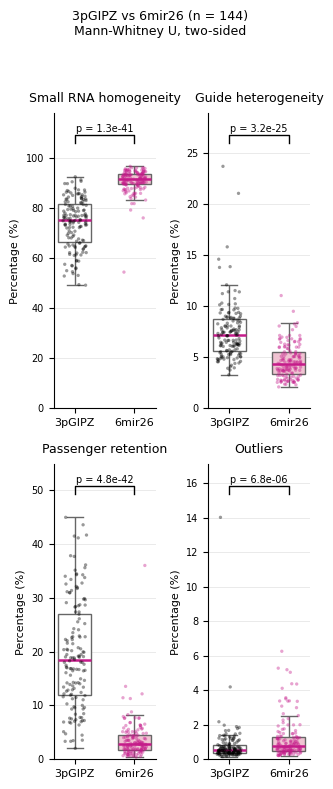

In [21]:
def draw_metric_boxplot_2(ax, metric, title, p_value):
    box_colors = {PAIR_A: 'white', PAIR_B: '#f8bbd0'}
    point_colors = {PAIR_A: 'black', PAIR_B: '#c51b8a'}

    sns.boxplot(
        data=dfMetricsFiltered,
        x='library', y=metric, order=ORDER_2, hue_order=ORDER_2,
        hue='library', palette=box_colors, dodge=False,
        width=0.55, linewidth=1.0, showfliers=False,
        medianprops={'color': '#c51b8a', 'linewidth': 1.8},
        whiskerprops={'color': '#666666'},
        capprops={'color': '#666666'},
        boxprops={'edgecolor': '#666666'},
        ax=ax,
    )
    sns.stripplot(
        data=dfMetricsFiltered,
        x='library', y=metric, order=ORDER_2, hue_order=ORDER_2,
        hue='library', palette=point_colors, dodge=False,
        size=2.4, alpha=0.40, jitter=0.20,
        ax=ax,
    )

    if hasattr(ax, 'legend_') and ax.legend_ is not None:
        ax.legend_.remove()

    pair_data = dfMetricsFiltered[dfMetricsFiltered['library'].isin(ORDER_2)]
    y_top = pair_data[metric].max() * 1.22
    ax.set_ylim(0, y_top)

    # Significance bracket
    y = y_top * 0.90
    h = y_top * 0.025
    ax.plot([0, 0, 1, 1], [y, y + h, y + h, y], color='black', linewidth=1.0, clip_on=False)
    ax.text(0.5, y + h * 1.15, 'p = {}'.format(format_p(p_value)),
            ha='center', va='bottom', fontsize=7)

    ax.set_title(title, fontsize=9, pad=8)
    ax.set_xlabel('')
    ax.set_ylabel('Percentage (%)', fontsize=8)
    ax.tick_params(axis='x', labelsize=8)
    ax.tick_params(axis='y', labelsize=7)
    ax.yaxis.grid(True, color='#e6e6e6', linewidth=0.6)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

# Combined 2 x 2 panel
fig, axes = plt.subplots(2, 2, figsize=(PAIRWISE_COMBINED_WIDTH, PAIRWISE_COMBINED_HEIGHT))
for ax, (metric, title, _) in zip(axes.ravel(), METRIC_SPECS):
    p_val = dfStats2.loc[dfStats2['metric'] == metric, 'p_value'].iloc[0]
    draw_metric_boxplot_2(ax, metric, title, p_val)
fig.suptitle('{} vs {} (n = {})\nMann-Whitney U, two-sided'.format(
    PAIR_A, PAIR_B, n_common), fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.95])

if SAVE_METRICS:
    stem_combined = 'metrics_5end_{}_vs_{}_combined'.format(PAIR_A, PAIR_B)
    for ext in ['pdf', 'png']:
        fig.savefig(PAIRWISE_OUT_DIR / '{}.{}'.format(stem_combined, ext),
                    dpi=300, bbox_inches='tight')
plt.show()

# Individual figures
if SAVE_METRICS:
    for metric, title, stem in METRIC_SPECS:
        p_val = dfStats2.loc[dfStats2['metric'] == metric, 'p_value'].iloc[0]
        fig, ax = plt.subplots(figsize=(PAIRWISE_INDIVIDUAL_WIDTH, PAIRWISE_INDIVIDUAL_HEIGHT))
        draw_metric_boxplot_2(ax, metric, title, p_val)
        fig.tight_layout()
        stem_pair = 'metrics_5end_{}_vs_{}_{}'.format(
            PAIR_A, PAIR_B, stem.replace('metrics_5end_', ''))
        for ext in ['pdf', 'png']:
            fig.savefig(PAIRWISE_OUT_DIR / '{}.{}'.format(stem_pair, ext),
                        dpi=300, bbox_inches='tight')
        plt.close(fig)


In [22]:
if SAVE_METRICS:
    dfStats2.to_csv(PAIRWISE_OUT_DIR / 'shRNA_metrics_5end_stats_{}_vs_{}.csv'.format(
        PAIR_A, PAIR_B), index=False)
    print('Saved 3pGIPZ vs 6mir26 statistics to {}'.format(PAIRWISE_OUT_DIR))

dfStats2


Saved 3pGIPZ vs 6mir26 statistics to /home/kwonschul/projects/shrek/deepseek/heatmap/metrics_5end_v2/3pGIPZ_vs_6mir26


,metric_label,metric,group_a,group_b,n_a,n_b,median_a,median_b,median_difference,U,p_value,q_value_bh,significance
0,Small RNA homogeneity,homogeneity_percent,3pGIPZ,6mir26,144,144,75.335211,91.644171,16.308960,819.0,1.331588e-41,2.663177e-41,****
1,Guide heterogeneity,heterogeneity_percent,3pGIPZ,6mir26,144,144,7.141734,4.377905,-2.763828,17701.0,3.187512e-25,4.250017e-25,****
2,Passenger retention,maturation_percent,3pGIPZ,6mir26,144,144,18.394739,2.790680,-15.604059,19970.0,4.793665e-42,1.917466e-41,****
3,Outliers,outlier_percent,3pGIPZ,6mir26,144,144,0.520082,0.764960,0.244878,7187.0,6.774788e-06,6.774788e-06,****


### Notes

- The magenta line in each box is the median; the box is the interquartile range (Q1-Q3); whiskers extend to 1.5 x IQR. Individual variants are shown as jittered points.
- **Small RNA homogeneity** is the fraction of all reads that start exactly at the intended guide 5' end. Higher values mean a more homogeneous guide 5' end.
- **Guide heterogeneity** is the fraction of reads in the guide window (+/-6 nt) that start at positions other than the intended guide 5' end. Higher values mean more heterogeneous DROSHA processing.
- **Passenger retention** is the fraction of guide-window + passenger-window reads that are in the passenger window. Higher values mean more passenger strand remaining.
- **Outliers** are reads outside both the guide and passenger windows. Higher values mean more off-target or aberrant small RNAs.
